# 03. Telco Churn - классификация

Бинарная классификация: предсказать `Churn` (No - клиент остался, Yes - ушёл).

**Датасет:** 7 043 * 21.

**Дисбаланс классов:** 73.5 / 26.5.

**План:**
1. Препроцессинг: `customerID`, `TotalCharges`, таргет.
2. Прогон 9 моделей на едином протоколе.
3. CatBoost с нативными категориальными признаками.
4. Сравнение с credit: меняется ли иерархия семейств.
5. Таблица результатов + bar plot.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from config import Config


warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

config = Config()
RANDOM_STATE = config.RANDOM_STATE
print(config)

Config(mode='local', credit='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\credit_risk_dataset.csv', churn='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\WA_Fn-UseC_-Telco-Customer-Churn.csv', demand='C:\\Users\\ikr\\PycharmProjects\\classification-regression-tabular-review\\data\\train.csv', random_state=42)


## Загрузка датасета

Берём только churn. Классификация сложнее, чем в credit:

- **меньше данных** (7k против 32k) - бустинг может недобрать;
- **больше категориальных** (15 против 4) - OneHot раздувает пространство;
- **`customerID`** - идентификатор, удаляем;
- **`TotalCharges`** - хранится как строка, приводим к числу.

In [2]:
df_churn = pd.read_csv(config.path_churn)
print("churn:", df_churn.shape)
df_churn.head()

churn: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Препроцессинг

**`customerID`** - удаляем, у него 7 043 уникальных значений.

**`TotalCharges`** - `pd.to_numeric(errors='coerce')`, пустые строки станут `NaN`, заполняем медианой (11 значений).

**Таргет** - `Churn` -> `map({'No': 0, 'Yes': 1})`.

**Итог:** 7 043 * 20, пропусков 0, доля класса 1 = 0.2654.

In [3]:
churn = df_churn.copy()

churn = churn.drop(columns=['customerID'])

churn['TotalCharges'] = pd.to_numeric(churn['TotalCharges'], errors='coerce')
churn['TotalCharges'] = churn['TotalCharges'].fillna(churn['TotalCharges'].median())

churn['Churn'] = churn['Churn'].map({'No': 0, 'Yes': 1})

X_churn = churn.drop(columns=['Churn'])
y_churn = churn['Churn']

print(f"shape: {churn.shape}")
print(f"пропуски: {churn.isna().sum().sum()}")
print(f"доля класса 1: {y_churn.mean():.4f}")

shape: (7043, 20)
пропуски: 0
доля класса 1: 0.2654


## Препроцессор

Тот же `ColumnTransformer`, что для credit. Отличаются только списки колонок:

- **числовые (4):** `SeniorCitizen`, `tenure`, `MonthlyCharges`, `TotalCharges`;
- **категориальные (15):** `gender`, `Partner`, ..., `PaymentMethod`.

`StandardScaler` к числам, `OneHotEncoder` к категориям.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


cat_cols_churn = X_churn.select_dtypes(include=['object', 'str']).columns.tolist()
num_cols_churn = X_churn.select_dtypes(exclude=['object', 'str']).columns.tolist()

preprocessor_churn = ColumnTransformer([
    ('num', StandardScaler(), num_cols_churn),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols_churn),
])

print(f"числовые ({len(num_cols_churn)}): {num_cols_churn}")
print(f"категориальные ({len(cat_cols_churn)}): {cat_cols_churn}")

числовые (4): ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
категориальные (15): ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## Сравнение 9 моделей

Тот же протокол, что для credit:

- `StratifiedKFold(5)` с `shuffle=True` и `random_state=42`;
- `scoring='roc_auc'`;
- один и тот же `preprocessor_churn` для всех моделей.

Ожидаемые отличия от credit:

- при малом датасете бустинг теряет преимущество;
- много категориальных -> OneHot создаёт разреженную матрицу;
- сигнал слабее -> std выше.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB


cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    'LogReg':       LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=RANDOM_STATE),
    'RandomForest': RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    'XGBoost':      XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                  eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1),
    'LightGBM':     LGBMClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                   random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
    'CatBoost':     CatBoostClassifier(iterations=200, depth=6, learning_rate=0.1,
                                       random_state=RANDOM_STATE, verbose=0),
    'kNN':          KNeighborsClassifier(n_neighbors=15, n_jobs=-1),
    'SVM':          SVC(kernel='rbf', C=1.0, probability=True, random_state=RANDOM_STATE),
    'NaiveBayes':   GaussianNB(),
}

results_churn = {}

for name, model in models.items():
    pipe = Pipeline([('prep', preprocessor_churn), ('model', model)])
    scores = cross_val_score(pipe, X_churn, y_churn, cv=cv, scoring='roc_auc', n_jobs=-1)
    results_churn[name] = (scores.mean(), scores.std())
    print(f"{name:15} ROC-AUC: {scores.mean():.4f} ± {scores.std():.4f}")

LogReg          ROC-AUC: 0.8450 ± 0.0134
DecisionTree    ROC-AUC: 0.7447 ± 0.0149
RandomForest    ROC-AUC: 0.8215 ± 0.0120
XGBoost         ROC-AUC: 0.8318 ± 0.0123
LightGBM        ROC-AUC: 0.8291 ± 0.0118
CatBoost        ROC-AUC: 0.8402 ± 0.0116
kNN             ROC-AUC: 0.8203 ± 0.0145
SVM             ROC-AUC: 0.7937 ± 0.0220
NaiveBayes      ROC-AUC: 0.8182 ± 0.0135


## CatBoost с нативными категориальными признаками

CatBoost умеет работать с категориями напрямую, без OneHot. Использует ordered target statistics.

Подаём `X_churn` как есть: числовые + категориальные. Указываем `cat_features` списком имён.

**Ключевое отличие от `cross_val_score`:** sklearn конвертирует DataFrame в numpy, и CatBoost теряет имена колонок. Поэтому пишем ручной цикл через `StratifiedKFold.split` и `iloc`, чтобы DataFrame сохранился.

Ожидаемые эффекты:

- среднее ROC-AUC примерно на уровне OneHot-версии;
- std должен упасть - ordered target statistics работает стабильнее.

In [6]:
from sklearn.metrics import roc_auc_score


cat_feature_names = X_churn.select_dtypes(include=['object', 'str']).columns.tolist()
cv_split = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores_list = []

for train_idx, val_idx in cv_split.split(X_churn, y_churn):
    X_tr = X_churn.iloc[train_idx]
    X_val = X_churn.iloc[val_idx]
    y_tr = y_churn.iloc[train_idx]
    y_val = y_churn.iloc[val_idx]

    model_native = CatBoostClassifier(
        iterations=200, depth=6, learning_rate=0.1,
        cat_features=cat_feature_names,
        random_state=RANDOM_STATE, verbose=0,
    )
    model_native.fit(X_tr, y_tr)
    y_proba = model_native.predict_proba(X_val)[:, 1]
    scores_list.append(roc_auc_score(y_val, y_proba))

scores_native = np.array(scores_list)
print(f"CatBoost native: {scores_native.mean():.4f} ± {scores_native.std():.4f}")
print(f"CatBoost OneHot: 0.8402 ± 0.0116")

results_churn['CatBoost_native'] = (scores_native.mean(), scores_native.std())

CatBoost native: 0.8424 ± 0.0099
CatBoost OneHot: 0.8402 ± 0.0116


## Таблица результатов

Сортировка по среднему ROC-AUC, убывание.

Топ-3 (LogReg, CatBoost-native, CatBoost) разделены менее чем на 0.005 - статистически неразличимы.

In [7]:
results_churn_df = (
    pd.DataFrame(results_churn, index=['mean', 'std'])
      .T
      .sort_values('mean', ascending=False)
)
print(results_churn_df)

print()
print("Модели в results_churn:", list(results_churn.keys()))
print("Всего:", len(results_churn))

                     mean       std
LogReg           0.844999  0.013361
CatBoost_native  0.842416  0.009886
CatBoost         0.840243  0.011640
XGBoost          0.831779  0.012266
LightGBM         0.829112  0.011835
RandomForest     0.821459  0.011959
kNN              0.820261  0.014548
NaiveBayes       0.818176  0.013472
SVM              0.793691  0.021967
DecisionTree     0.744746  0.014942

Модели в results_churn: ['LogReg', 'DecisionTree', 'RandomForest', 'XGBoost', 'LightGBM', 'CatBoost', 'kNN', 'SVM', 'NaiveBayes', 'CatBoost_native']
Всего: 10


## Bar plot

Топ-3 - зелёным, остальные - синим.

Усы - стандартное отклонение по 5 фолдам.

Пунктирная линия на 0.8 - ориентир, а не порог. Модели группируются вокруг 0.82-0.85.

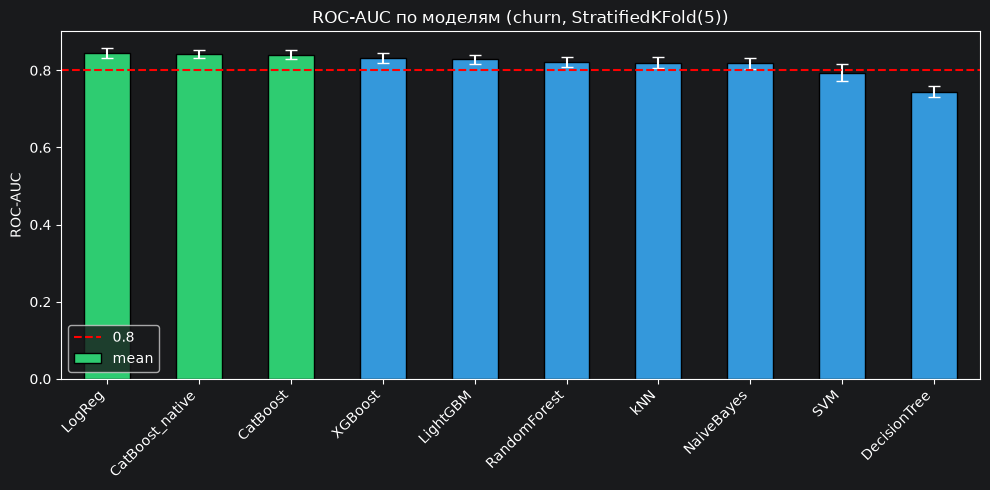

In [8]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#2ecc71' if i < 3 else '#3498db' for i in range(len(results_churn_df))]

results_churn_df['mean'].plot(
    kind='bar', yerr=results_churn_df['std'], ax=ax,
    color=colors, capsize=4, edgecolor='black'
)
ax.axhline(0.8, color='red', linestyle='--', label='0.8')
ax.set_title('ROC-AUC по моделям (churn, StratifiedKFold(5))')
ax.set_ylabel('ROC-AUC')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(config.churn_plot, dpi=150)
plt.show()

## Выводы

### Иерархия семейств перевернулась

На credit бустинг значимо превосходил LogReg (+0.080 ROC-AUC). На churn LogReg вышел на первое место.

Причины:

- малый датасет - бустингу нужно много данных, на 7k он недобирает;
- 15 категориальных признаков после OneHot дают бинарные флажки, неудобные для деревьев;
- сигнал слабее - бустинг шумит, LogReg сглаживает.

### Разброс (std) вырос в 4 раза

Средний std на credit около 0.003, на churn около 0.013. Малый датасет -> каждый фолд около 1 400 строк -> случайные колебания сильнее.

SVM - самая нестабильная (std = 0.0220). CatBoost-native - самый стабильный (std = 0.0099), что подтверждает эффект ordered target statistics. LogReg и NaiveBayes, наоборот, оказались среди наименее стабильных (std 0.0134 и 0.0135).

### DecisionTree деградировал

На credit DecisionTree показывал 0.9096, на churn - 0.7447. Одно дерево с `max_depth=10` на 7k данных запоминает train вместо закономерностей.

### CatBoost-native дал стабильность

Среднее ROC-AUC статистически не отличается от OneHot-версии (Δ = 0.0022). Но std упал на 15% (0.0116 -> 0.0099). Нативные категориальные признаки делают модель более устойчивой к разбиению на фолды.

### Сравнение credit vs churn

| Модель | Credit | Churn | Δ (падение) |
|---|---|---|---|
| XGBoost | 0.9498 | 0.8318 | -0.118 |
| LightGBM | 0.9491 | 0.8291 | -0.120 |
| CatBoost | 0.9422 | 0.8402 | -0.102 |
| RandomForest | 0.9325 | 0.8215 | -0.111 |
| DecisionTree | 0.9096 | 0.7447 | -0.165 |
| kNN | 0.8854 | 0.8203 | -0.065 |
| SVM | 0.8890 | 0.7937 | -0.095 |
| LogReg | 0.8702 | 0.8450 | -0.025 |
| NaiveBayes | 0.8317 | 0.8182 | -0.014 |

**Главный вывод:** преимущество бустинга не универсально. На малых датасетах с большим числом категориальных признаков линейные модели конкурентоспособны.

Протокол идентичен credit: `StratifiedKFold(5)`, `scoring='roc_auc'`, один и тот же `ColumnTransformer` по логике. Сравнение честное.